<a href="https://colab.research.google.com/github/mahendar8578/SmartSpend-AI/blob/main/SmartSpend_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 💰 SmartSpend AI
## AI-Powered Personal Finance Management System

**Objective:**  
Analyze income and expenses, automatically categorize transactions,
identify spending patterns, and provide AI-powered savings recommendations.

**Technology:** Python, Pandas, Matplotlib, Google Colab, Generative AI

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("SmartSpend AI - Project Started Successfully!")

SmartSpend AI - Project Started Successfully!


In [2]:
data = {
    "Date": [
        "2026-11-01",
        "2026-11-02",
        "2026-11-03",
        "2026-11-04",
        "2026-11-05",
        "2026-11-06",
        "2026-11-07",
        "2026-11-08"
    ],

    "Description": [
        "Salary",
        "Swiggy",
        "Petrol",
        "Amazon",
        "College Fee",
        "Movie",
        "Electricity Bill",
        "Grocery"
    ],

    "Amount": [
        30000,
        450,
        1200,
        2000,
        5000,
        300,
        1500,
        2500
    ],

    "Type": [
        "Income",
        "Expense",
        "Expense",
        "Expense",
        "Expense",
        "Expense",
        "Expense",
        "Expense"
    ]
}

df = pd.DataFrame(data)

df

,Date,Description,Amount,Type
0,2026-11-01,Salary,30000,Income
1,2026-11-02,Swiggy,450,Expense
2,2026-11-03,Petrol,1200,Expense
3,2026-11-04,Amazon,2000,Expense
4,2026-11-05,College Fee,5000,Expense
5,2026-11-06,Movie,300,Expense
6,2026-11-07,Electricity Bill,1500,Expense
7,2026-11-08,Grocery,2500,Expense


In [3]:
total_income = df[df["Type"] == "Income"]["Amount"].sum()
total_expenses = df[df["Type"] == "Expense"]["Amount"].sum()
remaining_balance = total_income - total_expenses

print("💰 Total Income: ₹", total_income)
print("💸 Total Expenses: ₹", total_expenses)
print("💵 Remaining Balance: ₹", remaining_balance)

💰 Total Income: ₹ 30000
💸 Total Expenses: ₹ 12950
💵 Remaining Balance: ₹ 17050


In [4]:
# Expense categories
categories = [
    "Food",
    "Transport",
    "Shopping",
    "Education",
    "Entertainment",
    "Bills",
    "Healthcare",
    "Other"
]

# Simple AI-style categorization function
def categorize_transaction(description):
    text = description.lower()

    if any(word in text for word in ["swiggy", "zomato", "restaurant", "food", "hotel"]):
        return "Food"

    elif any(word in text for word in ["petrol", "fuel", "uber", "ola", "bus", "metro"]):
        return "Transport"

    elif any(word in text for word in ["amazon", "flipkart", "shopping", "myntra"]):
        return "Shopping"

    elif any(word in text for word in ["college", "school", "course", "book", "education"]):
        return "Education"

    elif any(word in text for word in ["movie", "netflix", "spotify", "game"]):
        return "Entertainment"

    elif any(word in text for word in ["electricity", "water", "internet", "bill", "recharge"]):
        return "Bills"

    elif any(word in text for word in ["hospital", "medicine", "medical", "pharmacy"]):
        return "Healthcare"

    else:
        return "Other"


# Apply categorization only to expenses
df["Category"] = df.apply(
    lambda row: categorize_transaction(row["Description"])
    if row["Type"] == "Expense"
    else "Income",
    axis=1
)

df

,Date,Description,Amount,Type,Category
0,2026-11-01,Salary,30000,Income,Income
1,2026-11-02,Swiggy,450,Expense,Food
2,2026-11-03,Petrol,1200,Expense,Transport
3,2026-11-04,Amazon,2000,Expense,Shopping
4,2026-11-05,College Fee,5000,Expense,Education
5,2026-11-06,Movie,300,Expense,Entertainment
6,2026-11-07,Electricity Bill,1500,Expense,Bills
7,2026-11-08,Grocery,2500,Expense,Other


In [5]:
expense_data = df[df["Type"] == "Expense"]

category_spending = (
    expense_data
    .groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Spending by Category:")
print(category_spending)

Spending by Category:
Category
Education        5000
Other            2500
Shopping         2000
Bills            1500
Transport        1200
Food              450
Entertainment     300
Name: Amount, dtype: int64


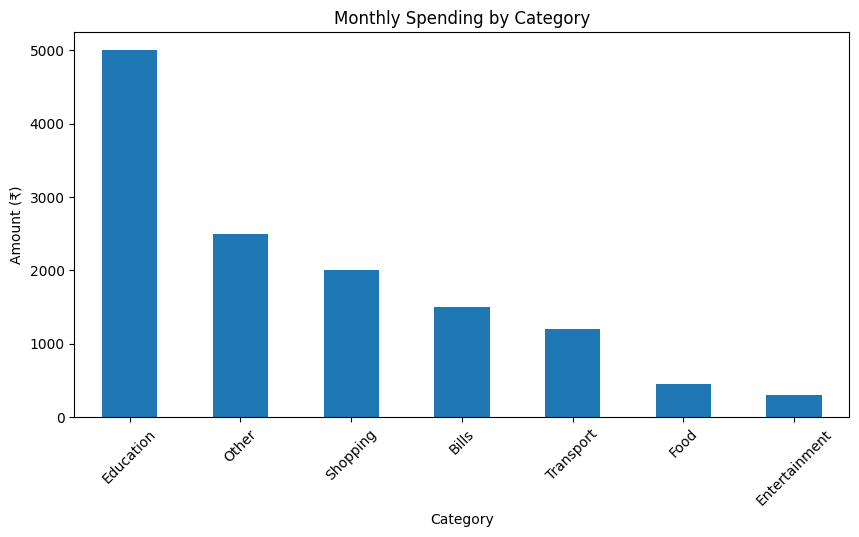

In [6]:
plt.figure(figsize=(10, 5))

category_spending.plot(kind="bar")

plt.title("Monthly Spending by Category")
plt.xlabel("Category")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)

plt.show()

In [9]:
!pip install -q "google-genai>=2.12.1,<3"

In [10]:
from google.colab import userdata
from google import genai

api_key = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=api_key)

print("Gemini AI connected successfully!")

Gemini AI connected successfully!


In [17]:
import time

def get_ai_recommendation(prompt, max_retries=4):
    for attempt in range(max_retries):
        try:
            response = client.models.generate_content(
                model="gemini-3.8-flash",
                contents=prompt
            )
            return response.text

        except Exception as e:
            if "503" in str(e):
                wait_time = 5 * (attempt + 1)
                print(f"AI service busy. Retrying in {wait_time} seconds...")
                time.sleep(wait_time)
            else:
                raise e

    return "AI service is temporarily unavailable. Please try again later."


ai_result = get_ai_recommendation(prompt)

print(ai_result)

AI service busy. Retrying in 5 seconds...
Here is a simple analysis of your monthly finances:

### 1. Spending Analysis
You are in a very strong financial position. You are spending only about **43% of your income** (₹12,950) and saving nearly **57%** (₹17,050), which is well above average. However, non-essential and untracked spending—specifically "Other" (₹2,500) and "Shopping" (₹2,000)—makes up about a third of your total expenses, meaning there is still room to optimize.

---

### 2. Highest Spending Category
* **Education:** **₹5,000** (This accounts for approximately 38.6% of your total monthly expenses). Since this is an investment in your personal or professional growth, it is generally considered a productive expense.

---

### 3. Two Practical Ways to Improve Savings
1. **Track the "Other" category:** At ₹2,500, "Other" is your second-largest expense. Break this down for a month to see where the money is going; small, untracked daily expenses often add up quickly.
2. **Apply 

In [18]:
# ============================================
# SmartSpend AI - Add New Transaction
# ============================================

description = input("Enter transaction description: ")
amount = float(input("Enter amount (₹): "))
transaction_type = input("Enter type (Income/Expense): ").capitalize()

# Categorize the transaction
if transaction_type == "Expense":
    category = categorize_transaction(description)
else:
    category = "Income"

# Create new transaction
new_transaction = pd.DataFrame({
    "Date": [pd.Timestamp.today().strftime("%Y-%m-%d")],
    "Description": [description],
    "Amount": [amount],
    "Type": [transaction_type],
    "Category": [category]
})

# Add transaction to our dataset
df = pd.concat([df, new_transaction], ignore_index=True)

print("\nTransaction added successfully!")
print(new_transaction)

Enter transaction description: Swiggy
Enter amount (₹): 450
Enter type (Income/Expense): Expense

Transaction added successfully!
         Date Description  Amount     Type Category
0  2026-11-06      Swiggy   450.0  Expense     Food


In [19]:
# Display all transactions

print("========== ALL TRANSACTIONS ==========")

display(df)


========== ALL TRANSACTIONS ==========


,Date,Description,Amount,Type,Category
0,2026-11-01,Salary,30000.0,Income,Income
1,2026-11-02,Swiggy,450.0,Expense,Food
2,2026-11-03,Petrol,1200.0,Expense,Transport
3,2026-11-04,Amazon,2000.0,Expense,Shopping
4,2026-11-05,College Fee,5000.0,Expense,Education
5,2026-11-06,Movie,300.0,Expense,Entertainment
6,2026-11-07,Electricity Bill,1500.0,Expense,Bills
7,2026-11-08,Grocery,2500.0,Expense,Other
8,2026-11-06,Swiggy,450.0,Expense,Food


In [20]:
# ============================================
# Updated Financial Summary
# ============================================

total_income = df[df["Type"] == "Income"]["Amount"].sum()
total_expenses = df[df["Type"] == "Expense"]["Amount"].sum()
remaining_balance = total_income - total_expenses

print("========== FINANCIAL SUMMARY ==========")
print(f"Total Income      : ₹{total_income:,.2f}")
print(f"Total Expenses    : ₹{total_expenses:,.2f}")
print(f"Remaining Balance : ₹{remaining_balance:,.2f}")


========== FINANCIAL SUMMARY ==========
Total Income      : ₹30,000.00
Total Expenses    : ₹13,400.00
Remaining Balance : ₹16,600.00


In [21]:
# ============================================
# Updated Spending Analysis
# ============================================

expense_data = df[df["Type"] == "Expense"]

category_spending = (
    expense_data
    .groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("========== SPENDING BY CATEGORY ==========")
print(category_spending)

========== SPENDING BY CATEGORY ==========
Category
Education        5000.0
Other            2500.0
Shopping         2000.0
Bills            1500.0
Transport        1200.0
Food              900.0
Entertainment     300.0
Name: Amount, dtype: float64


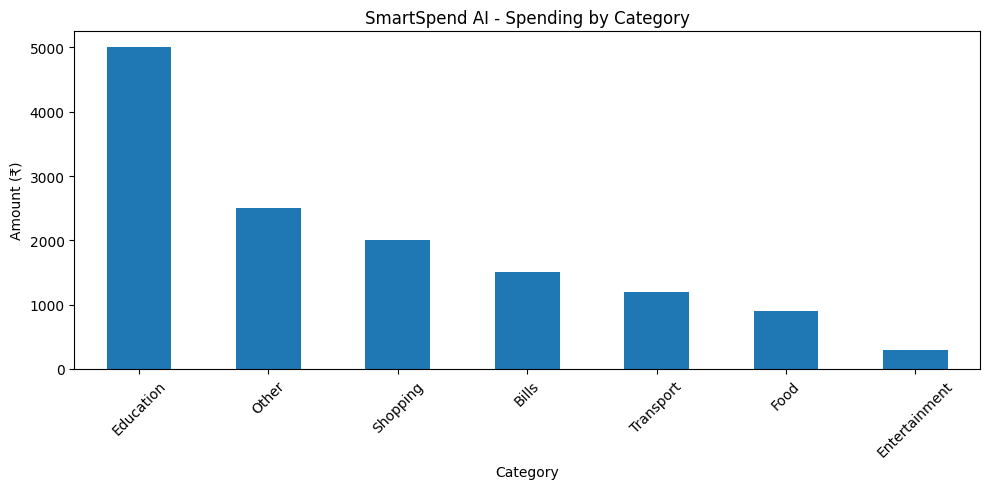

In [22]:
plt.figure(figsize=(10, 5))

category_spending.plot(kind="bar")

plt.title("SmartSpend AI - Spending by Category")
plt.xlabel("Category")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [26]:
# ============================================
# SmartSpend AI - Reliable AI Categorization
# ============================================

import time

VALID_CATEGORIES = [
    "Food",
    "Transport",
    "Shopping",
    "Education",
    "Entertainment",
    "Bills",
    "Healthcare",
    "Other"
]


def ai_categorize_transaction(description, max_retries=3):

    prompt = f"""
You are a financial transaction categorization assistant.

Categorize this transaction into exactly ONE category:

Food
Transport
Shopping
Education
Entertainment
Bills
Healthcare
Other

Transaction:
{description}

Return ONLY the category name.
"""


    for attempt in range(max_retries):

        try:

            response = client.models.generate_content(
                model="gemini-3.8-flash",
                contents=prompt
            )

            category = response.text.strip()

            # Clean AI response
            category = category.replace("*", "")
            category = category.replace(".", "")
            category = category.strip()

            # Check if valid category
            if category in VALID_CATEGORIES:
                return category

            return "Other"


        except Exception as e:

            error_message = str(e)

            if "503" in error_message:

                wait_time = 5 * (attempt + 1)

                print(
                    f"Gemini busy. "
                    f"Retrying in {wait_time} seconds..."
                )

                time.sleep(wait_time)

            else:

                print("AI Error:", error_message)
                return "Other"


    print("Gemini unavailable after retries.")
    return "Other"


print("AI categorization system ready!")

AI categorization system ready!


In [28]:
result = ai_categorize_transaction(
    "Bought dosa and coffee at a restaurant"
)

print("Transaction Category:", result)



Transaction Category: Food


In [29]:
# ============================================
# SmartSpend AI - Batch Transaction Categorization
# ============================================

def ai_categorize_transactions(descriptions):

    transaction_list = "\n".join(
        [f"{i+1}. {desc}" for i, desc in enumerate(descriptions)]
    )

    prompt = f"""
You are a financial transaction categorization assistant.

Categorize each transaction into exactly ONE of these categories:

Food
Transport
Shopping
Education
Entertainment
Bills
Healthcare
Other

Transactions:
{transaction_list}

Return ONLY the category names in the same order.
Return one category per line.
Do not add numbers or explanations.
"""

    try:

        response = client.models.generate_content(
            model="gemini-3.8-flash",
            contents=prompt
        )

        categories = [
            line.strip()
            for line in response.text.strip().split("\n")
            if line.strip()
        ]

        # Clean responses
        categories = [
            category.replace("*", "").replace(".", "").strip()
            for category in categories
        ]

        # Validate categories
        final_categories = []

        for category in categories:
            if category in VALID_CATEGORIES:
                final_categories.append(category)
            else:
                final_categories.append("Other")

        # Make sure output count matches input count
        while len(final_categories) < len(descriptions):
            final_categories.append("Other")

        return final_categories[:len(descriptions)]

    except Exception as e:

        print("Batch AI categorization error:", e)

        return ["Other"] * len(descriptions)


print("Batch AI categorization ready!")

Batch AI categorization ready!


In [30]:
test_transactions = [
    "Bought dosa and coffee at a restaurant",
    "Petrol for bike",
    "New shoes from online store",
    "Python programming course",
    "Netflix subscription",
    "Electricity bill",
    "Medicine from pharmacy"
]

test_categories = ai_categorize_transactions(test_transactions)

print("========== AI CATEGORIZATION TEST ==========")

for transaction, category in zip(test_transactions, test_categories):
    print(f"{transaction} → {category}")

Batch AI categorization error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
========== AI CATEGORIZATION TEST ==========
Bought dosa and coffee at a restaurant → Other
Petrol for bike → Other
New shoes from online store → Other
Python programming course → Other
Netflix subscription → Other
Electricity bill → Other
Medicine from pharmacy → Other


In [31]:
# ============================================
# SmartSpend AI - AI + Fallback Categorization
# ============================================

def fallback_category(description):

    text = description.lower()

    if any(word in text for word in [
        "dosa", "coffee", "restaurant", "food",
        "swiggy", "zomato", "hotel"
    ]):
        return "Food"

    elif any(word in text for word in [
        "petrol", "fuel", "uber", "ola",
        "bus", "metro", "transport"
    ]):
        return "Transport"

    elif any(word in text for word in [
        "shoe", "amazon", "shopping",
        "flipkart", "myntra"
    ]):
        return "Shopping"

    elif any(word in text for word in [
        "course", "college", "school",
        "python", "education", "book"
    ]):
        return "Education"

    elif any(word in text for word in [
        "netflix", "movie", "spotify",
        "game", "entertainment"
    ]):
        return "Entertainment"

    elif any(word in text for word in [
        "electricity", "water", "internet",
        "bill", "recharge"
    ]):
        return "Bills"

    elif any(word in text for word in [
        "medicine", "pharmacy", "hospital",
        "medical"
    ]):
        return "Healthcare"

    return "Other"


def ai_categorize_transactions(descriptions):

    transaction_list = "\n".join(
        [f"{i+1}. {desc}" for i, desc in enumerate(descriptions)]
    )

    prompt = f"""
Categorize each financial transaction into exactly one category.

Categories:
Food, Transport, Shopping, Education,
Entertainment, Bills, Healthcare, Other

Transactions:
{transaction_list}

Return ONLY the category names, one per line,
in the same order.
"""

    try:

        response = client.models.generate_content(
            model="gemini-3.8-flash",
            contents=prompt
        )

        categories = [
            line.strip().replace("*", "").replace(".", "")
            for line in response.text.strip().split("\n")
            if line.strip()
        ]

        if len(categories) == len(descriptions):

            valid = True

            for category in categories:
                if category not in VALID_CATEGORIES:
                    valid = False
                    break

            if valid:
                print("✅ Gemini AI categorization successful.")
                return categories

    except Exception as e:

        print("⚠️ Gemini unavailable. Using fallback categorization.")

    # Fallback
    print("🔄 Fallback categorization used.")

    return [
        fallback_category(description)
        for description in descriptions
    ]


print("SmartSpend AI categorization system ready!")

SmartSpend AI categorization system ready!


In [32]:
test_categories = ai_categorize_transactions(test_transactions)

print("\n========== AI CATEGORIZATION TEST ==========")

for transaction, category in zip(test_transactions, test_categories):
    print(f"{transaction} → {category}")

⚠️ Gemini unavailable. Using fallback categorization.
🔄 Fallback categorization used.

========== AI CATEGORIZATION TEST ==========
Bought dosa and coffee at a restaurant → Food
Petrol for bike → Transport
New shoes from online store → Shopping
Python programming course → Education
Netflix subscription → Entertainment
Electricity bill → Bills
Medicine from pharmacy → Healthcare


In [33]:
# ============================================
# SmartSpend AI - Categorize Existing Transactions
# ============================================

expense_mask = df["Type"] == "Expense"

expense_descriptions = df.loc[expense_mask, "Description"].tolist()

if expense_descriptions:

    categories = ai_categorize_transactions(expense_descriptions)

    df.loc[expense_mask, "Category"] = categories

print("========== UPDATED TRANSACTIONS ==========")
display(df)

⚠️ Gemini unavailable. Using fallback categorization.
🔄 Fallback categorization used.
========== UPDATED TRANSACTIONS ==========


,Date,Description,Amount,Type,Category
0,2026-11-01,Salary,30000.0,Income,Income
1,2026-11-02,Swiggy,450.0,Expense,Food
2,2026-11-03,Petrol,1200.0,Expense,Transport
3,2026-11-04,Amazon,2000.0,Expense,Shopping
4,2026-11-05,College Fee,5000.0,Expense,Education
5,2026-11-06,Movie,300.0,Expense,Entertainment
6,2026-11-07,Electricity Bill,1500.0,Expense,Bills
7,2026-11-08,Grocery,2500.0,Expense,Other
8,2026-11-06,Swiggy,450.0,Expense,Food


In [34]:
# ============================================
# SmartSpend AI - Updated Spending Analysis
# ============================================

expense_data = df[df["Type"] == "Expense"]

category_spending = (
    expense_data
    .groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("========== SPENDING BY CATEGORY ==========")
print(category_spending)

========== SPENDING BY CATEGORY ==========
Category
Education        5000.0
Other            2500.0
Shopping         2000.0
Bills            1500.0
Transport        1200.0
Food              900.0
Entertainment     300.0
Name: Amount, dtype: float64


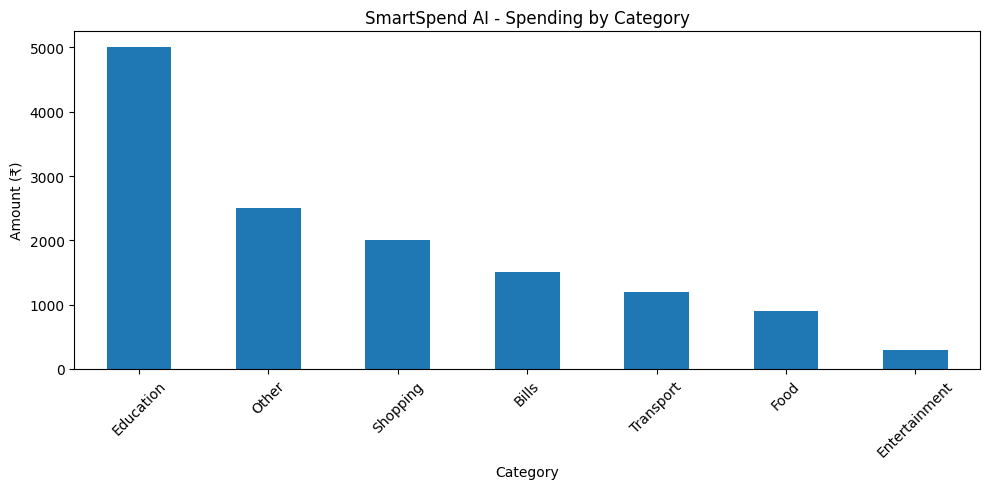

In [35]:
plt.figure(figsize=(10, 5))

category_spending.plot(kind="bar")

plt.title("SmartSpend AI - Spending by Category")
plt.xlabel("Category")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [36]:
# ============================================
# SmartSpend AI - Monthly Budget System
# ============================================

budgets = {
    "Food": 3000,
    "Transport": 2500,
    "Shopping": 3000,
    "Education": 6000,
    "Entertainment": 2000,
    "Bills": 2500,
    "Healthcare": 2000,
    "Other": 1500
}

print("========== MONTHLY BUDGETS ==========")

for category, budget in budgets.items():
    print(f"{category:<15} ₹{budget:,.2f}")

========== MONTHLY BUDGETS ==========
Food            ₹3,000.00
Transport       ₹2,500.00
Shopping        ₹3,000.00
Education       ₹6,000.00
Entertainment   ₹2,000.00
Bills           ₹2,500.00
Healthcare      ₹2,000.00
Other           ₹1,500.00


In [37]:
# ============================================
# SmartSpend AI - Budget Warning Analysis
# ============================================

print("========== BUDGET ANALYSIS ==========\n")

budget_warnings = []

for category, budget in budgets.items():

    spent = category_spending.get(category, 0)

    percentage = (spent / budget) * 100

    print(
        f"{category}: "
        f"Spent ₹{spent:,.2f} / "
        f"Budget ₹{budget:,.2f} "
        f"({percentage:.1f}%)"
    )

    if percentage >= 100:
        print("🔴 WARNING: Budget exceeded!")

        budget_warnings.append(
            f"{category} budget exceeded"
        )

    elif percentage >= 80:
        print("🟠 WARNING: Spending is above 80% of budget.")

        budget_warnings.append(
            f"{category} spending reached {percentage:.1f}%"
        )

    else:
        print("🟢 Within budget.")

    print()

========== BUDGET ANALYSIS ==========

Food: Spent ₹900.00 / Budget ₹3,000.00 (30.0%)
🟢 Within budget.

Transport: Spent ₹1,200.00 / Budget ₹2,500.00 (48.0%)
🟢 Within budget.

Shopping: Spent ₹2,000.00 / Budget ₹3,000.00 (66.7%)
🟢 Within budget.

Education: Spent ₹5,000.00 / Budget ₹6,000.00 (83.3%)
🟠 WARNING: Spending is above 80% of budget.

Entertainment: Spent ₹300.00 / Budget ₹2,000.00 (15.0%)
🟢 Within budget.

Bills: Spent ₹1,500.00 / Budget ₹2,500.00 (60.0%)
🟢 Within budget.

Healthcare: Spent ₹0.00 / Budget ₹2,000.00 (0.0%)
🟢 Within budget.

Other: Spent ₹2,500.00 / Budget ₹1,500.00 (166.7%)
🔴 WARNING: Budget exceeded!



In [38]:
# ============================================
# SmartSpend AI - Personalized Savings Advice
# ============================================

warning_text = "\n".join(budget_warnings)

if not warning_text:
    warning_text = "No category has reached 80% of its monthly budget."


recommendation_prompt = f"""
You are SmartSpend AI, a personal finance assistant.

Analyze this user's monthly financial information.

Income: ₹{total_income:,.2f}
Expenses: ₹{total_expenses:,.2f}
Remaining Balance: ₹{remaining_balance:,.2f}

Spending by Category:
{category_spending.to_string()}

Budget Warnings:
{warning_text}

Give:
1. A short summary of the spending pattern.
2. The category that needs the most attention.
3. Two practical ways to reduce unnecessary spending.
4. One simple monthly savings goal.

Keep the advice simple and practical.

Do not recommend stocks, cryptocurrencies,
loans, or specific financial products.
"""


def get_savings_recommendation(prompt):

    try:

        response = client.models.generate_content(
            model="gemini-3.8-flash",
            contents=prompt
        )

        return response.text

    except Exception as e:

        print("⚠️ Gemini is currently unavailable.")

        return (
            "AI recommendation is temporarily unavailable. "
            "Please review the budget warnings above."
        )


ai_savings_advice = get_savings_recommendation(
    recommendation_prompt
)

print("\n========== SMARTSPEND AI ADVICE ==========\n")
print(ai_savings_advice)

⚠️ Gemini is currently unavailable.

========== SMARTSPEND AI ADVICE ==========

AI recommendation is temporarily unavailable. Please review the budget warnings above.


In [39]:
# ============================================
# SmartSpend AI - Savings Recommendation
# ============================================

def fallback_savings_advice():

    if category_spending.empty:
        return "Start adding expenses to receive spending recommendations."

    highest_category = category_spending.idxmax()
    highest_amount = category_spending.max()

    advice = []

    advice.append(
        f"Your highest spending category is "
        f"{highest_category} at ₹{highest_amount:,.2f}."
    )

    # Find categories close to or above budget
    for category, budget in budgets.items():

        spent = category_spending.get(category, 0)

        if spent >= budget:
            advice.append(
                f"Your {category} spending has exceeded "
                f"the monthly budget. Try reducing unnecessary "
                f"{category.lower()} expenses."
            )

        elif spent >= budget * 0.8:
            advice.append(
                f"Your {category} spending has reached "
                f"{(spent / budget) * 100:.1f}% of the budget. "
                f"Monitor this category carefully."
            )

    savings_goal = remaining_balance * 0.20

    advice.append(
        f"A simple target is to save at least "
        f"₹{savings_goal:,.2f} from your remaining balance."
    )

    return "\n".join(
        [f"{i+1}. {item}" for i, item in enumerate(advice)]
    )


def get_savings_recommendation(prompt):

    try:

        response = client.models.generate_content(
            model="gemini-3.8-flash",
            contents=prompt
        )

        return response.text

    except Exception:

        print("⚠️ Gemini temporarily unavailable.")
        print("🔄 Using SmartSpend fallback recommendation.\n")

        return fallback_savings_advice()


ai_savings_advice = get_savings_recommendation(
    recommendation_prompt
)

print("\n========== SMARTSPEND AI ADVICE ==========\n")
print(ai_savings_advice)

⚠️ Gemini temporarily unavailable.
🔄 Using SmartSpend fallback recommendation.


========== SMARTSPEND AI ADVICE ==========

1. Your highest spending category is Education at ₹5,000.00.
2. Your Education spending has reached 83.3% of the budget. Monitor this category carefully.
3. Your Other spending has exceeded the monthly budget. Try reducing unnecessary other expenses.
4. A simple target is to save at least ₹3,320.00 from your remaining balance.


In [40]:
# ============================================
# SMARTSPEND AI - FINAL DASHBOARD
# ============================================

print("=" * 55)
print("              💰 SMARTSPEND AI")
print("       AI-Powered Personal Finance System")
print("=" * 55)

print("\n📊 FINANCIAL SUMMARY")
print("-" * 55)
print(f"Total Income      : ₹{total_income:,.2f}")
print(f"Total Expenses    : ₹{total_expenses:,.2f}")
print(f"Remaining Balance : ₹{remaining_balance:,.2f}")

print("\n📈 SPENDING BY CATEGORY")
print("-" * 55)

for category, amount in category_spending.items():
    print(f"{category:<18} ₹{amount:,.2f}")

print("\n⚠️ BUDGET WARNINGS")
print("-" * 55)

if budget_warnings:
    for warning in budget_warnings:
        print("•", warning)
else:
    print("✅ All categories are within budget.")

print("\n🤖 AI FINANCIAL ADVICE")
print("-" * 55)
print(ai_savings_advice)

print("\n" + "=" * 55)
print("           SmartSpend AI Dashboard Complete")
print("=" * 55)

              💰 SMARTSPEND AI
       AI-Powered Personal Finance System

📊 FINANCIAL SUMMARY
-------------------------------------------------------
Total Income      : ₹30,000.00
Total Expenses    : ₹13,400.00
Remaining Balance : ₹16,600.00

📈 SPENDING BY CATEGORY
-------------------------------------------------------
Education          ₹5,000.00
Other              ₹2,500.00
Shopping           ₹2,000.00
Bills              ₹1,500.00
Transport          ₹1,200.00
Food               ₹900.00
Entertainment      ₹300.00

⚠️ BUDGET WARNINGS
-------------------------------------------------------
• Education spending reached 83.3%
• Other budget exceeded

🤖 AI FINANCIAL ADVICE
-------------------------------------------------------
1. Your highest spending category is Education at ₹5,000.00.
2. Your Education spending has reached 83.3% of the budget. Monitor this category carefully.
3. Your Other spending has exceeded the monthly budget. Try reducing unnecessary other expenses.
4. A simple ta

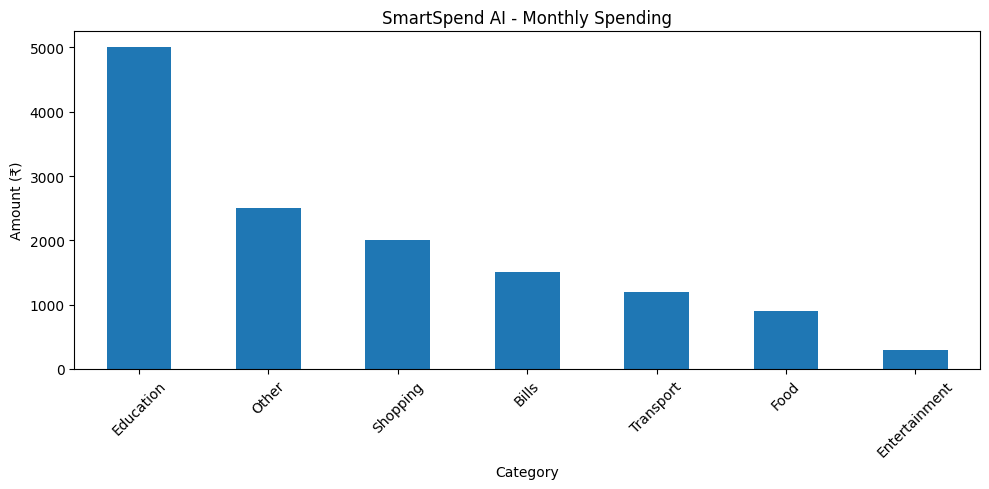

In [41]:
# ============================================
# SmartSpend AI - Spending Chart
# ============================================

plt.figure(figsize=(10, 5))

category_spending.plot(kind="bar")

plt.title("SmartSpend AI - Monthly Spending")
plt.xlabel("Category")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [42]:
# ============================================
# SmartSpend AI - Create Transactions Dataset
# ============================================

df.to_csv("transactions.csv", index=False)

print("✅ transactions.csv created successfully!")
print(f"Total transactions: {len(df)}")

✅ transactions.csv created successfully!
Total transactions: 9


In [43]:
# Display saved dataset

dataset = pd.read_csv("transactions.csv")

print("========== TRANSACTIONS DATASET ==========")
display(dataset)

========== TRANSACTIONS DATASET ==========


,Date,Description,Amount,Type,Category
0,2026-11-01,Salary,30000.0,Income,Income
1,2026-11-02,Swiggy,450.0,Expense,Food
2,2026-11-03,Petrol,1200.0,Expense,Transport
3,2026-11-04,Amazon,2000.0,Expense,Shopping
4,2026-11-05,College Fee,5000.0,Expense,Education
5,2026-11-06,Movie,300.0,Expense,Entertainment
6,2026-11-07,Electricity Bill,1500.0,Expense,Bills
7,2026-11-08,Grocery,2500.0,Expense,Other
8,2026-11-06,Swiggy,450.0,Expense,Food


In [44]:
from google.colab import files

files.download("transactions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>